# 05 - Evaluation over time

Two questions about the time-based evaluation:

1. How different are the results with a random split instead of a time split?
2. Is the drop on later years a steady trend, and does retraining on recent data help?

LightGBM with the tuned parameters from notebook 03 is used here, because it trains in about a minute
(Random Forest gives almost the same scores but takes about ten times longer).

## Settings

In [1]:
MODEL = "LightGBM"
ROLLING_YEARS = range(2014, 2023)   # each year is tested by a model trained on the years before it
WINDOW_YEARS = 5                    # length of the sliding window
RANDOM_TEST_SHARE = 0.2
RANDOM_STATE = 42

In [2]:
import sys, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score, roc_auc_score

ROOT = Path.cwd().parent
sys.path.append(str(ROOT / "src"))
from load_data import load_raw
from prepare import clean, build_dataset
from features import build_features, feature_groups
from modeling import make_preprocessor, make_models

FIG, OUT = ROOT / "figures", ROOT / "outputs"
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore")

best_params = json.loads((OUT / "best_params.json").read_text())[MODEL]
df = clean(load_raw())
data = build_dataset(df)

def fit_score(train, test):
    numeric, categorical, text = feature_groups(train.columns)
    X_cols = numeric + categorical + [text]
    pipe = Pipeline([("pre", make_preprocessor(numeric, categorical, text)),
                     ("model", clone(make_models()[MODEL]))]).set_params(**best_params)
    pipe.fit(train[X_cols], train["failed"])
    p = pipe.predict_proba(test[X_cols])[:, 1]
    return {"PR-AUC": average_precision_score(test["failed"], p), "ROC-AUC": roc_auc_score(test["failed"], p),
            "test failure rate": test["failed"].mean()}

Loaded 364,115 rows, dropped 123 malformed rows


## 1. Random split vs. time split

The random split uses the same 2000-2022 applications, 80% for training and 20% for testing, stratified by the label.
The history features are rebuilt for this split, so the test rows get failure rates computed from training
applications of **all** years, including later ones. This is exactly what a random split means in practice:
the model gets information from the future of the applications it is tested on.

In [3]:
rows = []
time_feats = build_features(df, data)
rows.append({"split": "time (train 2000-2018, test 2019-2022)",
             **fit_score(time_feats[time_feats["is_train"]], time_feats[~time_feats["is_train"]])})

train_idx, _ = train_test_split(np.arange(len(data)), test_size=RANDOM_TEST_SHARE,
                                stratify=data["failed"], random_state=RANDOM_STATE)
mask = np.zeros(len(data), bool)
mask[train_idx] = True
random_feats = build_features(df, data, train_mask=mask)
rows.append({"split": "random 80/20",
             **fit_score(random_feats[random_feats["is_train"]], random_feats[~random_feats["is_train"]])})

split_table = pd.DataFrame(rows).set_index("split").round(3)
split_table

,PR-AUC,ROC-AUC,test failure rate
split,,,
"time (train 2000-2018, test 2019-2022)",0.353,0.728,0.139
random 80/20,0.598,0.841,0.150


**Random vs. time.** The same model gets PR-AUC 0.60 on a random split and 0.35 on the time split (ROC-AUC 0.84 vs 0.73).
A random split would make the model look about 70% better than it really is for new applications.
Two things cause the gap: the model is trained on applications from the same years it is tested on, and the
owner and attorney failure rates of the test rows include outcomes from later years.

## 2. Rolling evaluation, one year at a time

For each test year t, the features are rebuilt with t-1 as the last training year (so the failure rates
use only labels before t), a model is trained and the year t is scored. Two training choices are compared:

- **expanding window:** all years from 2000 up to t-1
- **sliding window:** only the last 5 years before t

In [4]:
rolling = []
for year in ROLLING_YEARS:
    subset = data[data["filing_year"] <= year].reset_index(drop=True)
    feats = build_features(df, subset, train_last_year=year - 1)
    test = feats[feats["filing_year"] == year]
    expanding = feats[feats["filing_year"] < year]
    sliding = expanding[expanding["filing_year"] >= year - WINDOW_YEARS]
    for name, train in [("expanding", expanding), (f"sliding {WINDOW_YEARS} years", sliding)]:
        rolling.append({"test year": year, "training": name, "train rows": len(train), **fit_score(train, test)})
rolling = pd.DataFrame(rolling)
rolling.to_csv(OUT / "rolling_evaluation.csv", index=False)
rolling.pivot(index="test year", columns="training", values="PR-AUC").round(3)

training,expanding,sliding 5 years
test year,,
2014,0.500,0.499
2015,0.516,0.527
2016,0.438,0.464
2017,0.464,0.465
2018,0.434,0.433
2019,0.419,0.432
2020,0.382,0.360
2021,0.328,0.305
2022,0.343,0.323


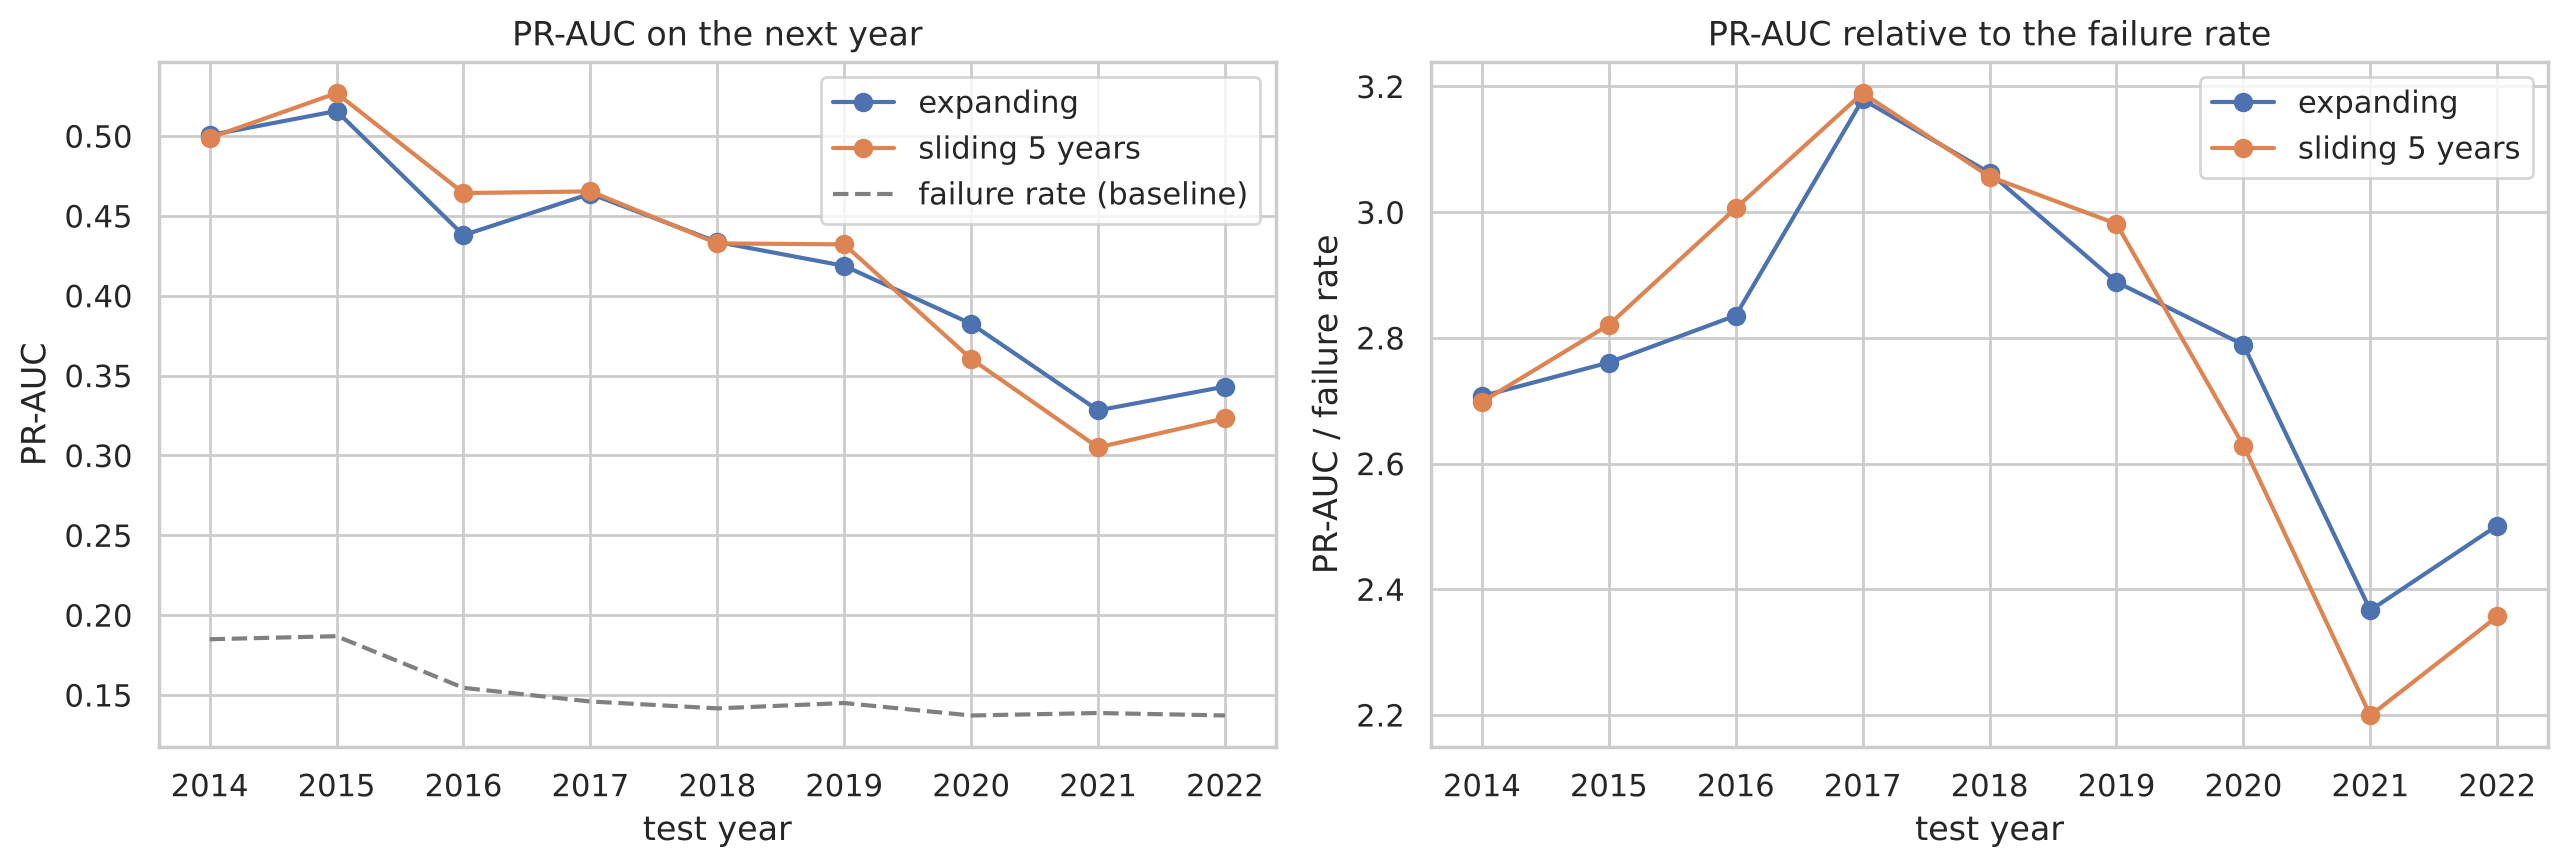

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, g in rolling.groupby("training"):
    axes[0].plot(g["test year"], g["PR-AUC"], marker="o", label=name)
    axes[1].plot(g["test year"], g["PR-AUC"] / g["test failure rate"], marker="o", label=name)
base = rolling.drop_duplicates("test year")
axes[0].plot(base["test year"], base["test failure rate"], color="grey", ls="--", label="failure rate (baseline)")
axes[0].set(title="PR-AUC on the next year", xlabel="test year", ylabel="PR-AUC")
axes[1].set(title="PR-AUC relative to the failure rate", xlabel="test year", ylabel="PR-AUC / failure rate")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.savefig(FIG / "rolling_evaluation.png", dpi=120)
plt.show()

**Year by year.** Even when the model is retrained every year, PR-AUC drops from about 0.50 (2014-2015) to about 0.33-0.34
(2021-2022). So the drop in notebook 03 is not only because the history features got old: the later years are harder to predict.
Part of it is that failures became rarer (19% in 2014-2015, 14% in 2020-2022). Relative to the failure rate (right plot),
the model is about as good until 2020, and the real drop is in 2021-2022.

Retraining helps a little in the later years: retrained every year, the model scores 0.33-0.34 on 2021-2022, compared with
0.31 for the model trained once on data up to 2018 (notebook 03).

Training only on the last 5 years is as good or a bit better up to 2019, and worse after that (2020-2022).
Older applications still help, so if the model were used in practice, the better option would be to retrain every year
on all the data so far, not only on recent years.

One limitation: the failure rates of the owner and attorney use all outcomes up to the year before the test year,
even though some of those applications may not have been decided yet at that point.